In [2]:
%pip install xgboost

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
import datetime as dt
from sklearn.inspection import permutation_importance

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
# Read in datasets
base = "https://raw.githubusercontent.com/mattcollinsPSU/group13_ds340w_fall2026_repo/main/data/"

mlb_dv_train = pd.read_csv(base + "mlb_dv_train.csv")
mlb_dv_val = pd.read_csv(base + "mlb_dv_val.csv")
mlb_dv_test = pd.read_csv(base + "mlb_dv_test.csv")

In [4]:
print(mlb_dv_train.shape)
print(mlb_dv_test.shape)
print(mlb_dv_val.shape)

(8607, 119)
(2460, 119)
(1229, 119)


In [5]:
pd.set_option('display.max_columns', None)
mlb_dv_train.head(5)

,Unnamed: 0,incident_date,team,ori,game_pk,homefavor,accuracy,game_date,venue_name,venue_id,temperature,other_weather,wind,attendance,start_time,elapsed_time,game_type,status_ind,home_league_id,isTie,gameNumber,publicFacing,doubleHeader,gamedayType,tiebreaker,dayNight,scheduledInnings,reverseHomeAwayStatus,gamesInSeries,seriesGameNumber,seriesDescription,ifNecessaryDescription,teams.away.score,teams.away.leagueRecord.pct,teams.home.score,teams.home.leagueRecord.pct,status.codedGameState,status.detailedState,homewin,awaywin,umpirechangedoutcome,hometeam,dv_hour_0,dv_hour_1,dv_hour_2,dv_hour_3,dv_hour_4,dv_hour_5,dv_hour_6,dv_hour_7,dv_hour_8,dv_hour_9,dv_hour_10,dv_hour_11,dv_hour_12,dv_hour_13,dv_hour_14,dv_hour_15,dv_hour_16,dv_hour_17,dv_hour_18,dv_hour_19,dv_hour_20,dv_hour_21,dv_hour_22,dv_hour_23,dayofweek,month,year,elapsed_time_clean,end_time,game_end_time,start_time_1,game_start_time,win,lose,inaccuracy,dvcount_10pmto6am,dvcount_8pmto6am,dvcount_6pmto6am,dvcount_4pmto4am,dvcount_2pmto2am,dvcount_noontomidnight,dvcount_noonto2pm,dvcount_2pmto4pm,dvcount_4pmto6pm,dvcount_6pmto8pm,dvcount_8pmto10pm,dvcount_10pmtomidnight,dvcount_midnightto2am,dvcount_2amto4am,dvcount_4amto6am,holiday,AQI,AQI_Category,closegame,closerecords,inaccuracy_bin,yearly_avg_attendance,game_end_hour,game_start_hour,dv_hour_24,dv_hour_25,dv_hour_26,dv_hour_27,dv_hour_28,dv_hour_29,dv_hour_30,total_dv,dv_post_game,dv_pre_game,dv_in_game,favor,disfavor,favored,disfavored,disfavor_bin,top25inaccurate,top25disfavor
0,0,4/6/2009,CLE,OHCLP0000,244195,0.315522,80.303030,4/6/2009,Rangers Ballpark in Arlington,13,49,Sunny,"12 mph, Out To CF",49916,13:06:00,2:33,R,F,103,False,1,True,N,E,N,day,9,False,3,1,Regular Season,Normal Game,1,0.0,9,1.0,F,Final,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,3,1,0,0,2,1,0,0,0,Mon,4,2009,2:33,15H 39M 0S,15.650000,13H 6M 0S,13.100000,0,1,19.696970,1,2,4,5,8,8,0,4,1,0,3,0,0,1,0,0,39,Good,0,0,Above 95%,25294.51282,15,13,0,0,0,1,0,0,0,10,8,1,1,-0.315522,0.315522,0,1,75%,1,0
1,1,4/6/2009,COL,CODPD0000,244196,0.603193,87.974684,4/6/2009,Chase Field,15,80,Roof Closed,"0 mph, None",48796,12:40:00,2:58,R,F,104,False,1,True,N,E,N,day,9,False,3,1,Regular Season,Normal Game,8,0.0,9,1.0,F,Final,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Mon,4,2009,2:58,14H 98M 0S,15.633333,12H 40M 0S,12.666667,0,1,12.025316,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,41,Good,1,0,50%,32309.54321,15,12,0,0,0,0,0,0,0,1,0,1,0,-0.603193,0.603193,0,1,95%,0,1
2,2,4/6/2009,DET,MI8234900,244197,-0.124916,90.322581,4/6/2009,Rogers Centre,14,68,Roof Closed,"0 mph, None",48027,19:21:00,2:43 (:09 delay),R,F,103,False,1,True,N,E,N,night,9,False,4,1,Regular Season,Normal Game,5,0.0,12,1.0,F,Final,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,1,0,0,1,0,Mon,4,2009,2:43,21H 64M 0S,22.066667,19H 21M 0S,19.350000,0,1,9.677419,1,1,3,4,4,4,0,0,1,1,1,1,0,0,0,0,34,Good,0,0,25%,30626.22293,22,19,0,0,0,0,0,0,0,5,1,3,1,0.124916,-0.124916,1,0,50%,0,0
3,3,4/7/2009,COL,CODPD0000,244208,0.687492,90.410959,4/7/2009,Chase Field,15,88,Clear,"8 mph, L To R",26558,18:40:00,2:41,R,F,104,False,1,True,N,E,N,night,9,False,3,2,Regular Season,Normal Game,3,0.5,0,0.5,F,Final,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,Tue,4,2009,2:41,20H 81M 0S,21.350000,18H 40M 0S,18.666667,1,0,9.589041,0,1,1,1,1,1,0,0,0,0,0,1,0,0,0,0,46,Good,0,1,25%,32309.54321,21,18,0,0,0,0,0,0,0,2,1,1,0,-0.687492,0.687492,0,1,95%,0,1
4,4,4/7/2009,DET,MI8234900,244209,-0.291465,92.028986,4/7/2009,Rogers Centre,14,68,Roof Closed,"0 mph, None",16790,19:08:00,2:40,R,F,103,False,1,True,N,E,N,night,9,False,4,2,Regular Season,Normal Game,4,0.0,5,1.0,F,Final,1,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,2,0,1,1,0,1,1,1,0,0,2,1,Tue,4,2009,2:40,21H 48M 0S,21.800000,19H 8M 0S,19.133333,0,1,7.971014,5,5,7,8,9,10,2,2,1,2,1,2,1,1,0,0,33,Good,1,0,5%,30626.22293,21,19,0,1,0,1,0,0,0,13,5,7,1,0.291465,-0.291465,1,0,50%,0,0


# Variable Encoding

In [6]:
# Create one-hot encoded variables
mlb_dv_train = pd.get_dummies(mlb_dv_train, columns=["team", "dayofweek", "dayNight"], drop_first=False, dtype=float)
mlb_dv_test = pd.get_dummies(mlb_dv_test, columns=["team", "dayofweek", "dayNight"], drop_first=False, dtype=float)
mlb_dv_val = pd.get_dummies(mlb_dv_val, columns=["team", "dayofweek", "dayNight"], drop_first=False, dtype=float)

mlb_dv_train.head(5)

,Unnamed: 0,incident_date,ori,game_pk,homefavor,accuracy,game_date,venue_name,venue_id,temperature,other_weather,wind,attendance,start_time,elapsed_time,game_type,status_ind,home_league_id,isTie,gameNumber,publicFacing,doubleHeader,gamedayType,tiebreaker,scheduledInnings,reverseHomeAwayStatus,gamesInSeries,seriesGameNumber,seriesDescription,ifNecessaryDescription,teams.away.score,teams.away.leagueRecord.pct,teams.home.score,teams.home.leagueRecord.pct,status.codedGameState,status.detailedState,homewin,awaywin,umpirechangedoutcome,hometeam,dv_hour_0,dv_hour_1,dv_hour_2,dv_hour_3,dv_hour_4,dv_hour_5,dv_hour_6,dv_hour_7,dv_hour_8,dv_hour_9,dv_hour_10,dv_hour_11,dv_hour_12,dv_hour_13,dv_hour_14,dv_hour_15,dv_hour_16,dv_hour_17,dv_hour_18,dv_hour_19,dv_hour_20,dv_hour_21,dv_hour_22,dv_hour_23,month,year,elapsed_time_clean,end_time,game_end_time,start_time_1,game_start_time,win,lose,inaccuracy,dvcount_10pmto6am,dvcount_8pmto6am,dvcount_6pmto6am,dvcount_4pmto4am,dvcount_2pmto2am,dvcount_noontomidnight,dvcount_noonto2pm,dvcount_2pmto4pm,dvcount_4pmto6pm,dvcount_6pmto8pm,dvcount_8pmto10pm,dvcount_10pmtomidnight,dvcount_midnightto2am,dvcount_2amto4am,dvcount_4amto6am,holiday,AQI,AQI_Category,closegame,closerecords,inaccuracy_bin,yearly_avg_attendance,game_end_hour,game_start_hour,dv_hour_24,dv_hour_25,dv_hour_26,dv_hour_27,dv_hour_28,dv_hour_29,dv_hour_30,total_dv,dv_post_game,dv_pre_game,dv_in_game,favor,disfavor,favored,disfavored,disfavor_bin,top25inaccurate,top25disfavor,team_CIN,team_CLE,team_COL,team_DET,team_KC,team_MIL,team_SEA,team_TEX,dayofweek_Fri,dayofweek_Mon,dayofweek_Sat,dayofweek_Sun,dayofweek_Thu,dayofweek_Tue,dayofweek_Wed,dayNight_day,dayNight_night
0,0,4/6/2009,OHCLP0000,244195,0.315522,80.303030,4/6/2009,Rangers Ballpark in Arlington,13,49,Sunny,"12 mph, Out To CF",49916,13:06:00,2:33,R,F,103,False,1,True,N,E,N,9,False,3,1,Regular Season,Normal Game,1,0.0,9,1.0,F,Final,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,3,1,0,0,2,1,0,0,0,4,2009,2:33,15H 39M 0S,15.650000,13H 6M 0S,13.100000,0,1,19.696970,1,2,4,5,8,8,0,4,1,0,3,0,0,1,0,0,39,Good,0,0,Above 95%,25294.51282,15,13,0,0,0,1,0,0,0,10,8,1,1,-0.315522,0.315522,0,1,75%,1,0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,1,4/6/2009,CODPD0000,244196,0.603193,87.974684,4/6/2009,Chase Field,15,80,Roof Closed,"0 mph, None",48796,12:40:00,2:58,R,F,104,False,1,True,N,E,N,9,False,3,1,Regular Season,Normal Game,8,0.0,9,1.0,F,Final,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,4,2009,2:58,14H 98M 0S,15.633333,12H 40M 0S,12.666667,0,1,12.025316,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,41,Good,1,0,50%,32309.54321,15,12,0,0,0,0,0,0,0,1,0,1,0,-0.603193,0.603193,0,1,95%,0,1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,2,4/6/2009,MI8234900,244197,-0.124916,90.322581,4/6/2009,Rogers Centre,14,68,Roof Closed,"0 mph, None",48027,19:21:00,2:43 (:09 delay),R,F,103,False,1,True,N,E,N,9,False,4,1,Regular Season,Normal Game,5,0.0,12,1.0,F,Final,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,1,0,0,1,0,4,2009,2:43,21H 64M 0S,22.066667,19H 21M 0S,19.350000,0,1,9.677419,1,1,3,4,4,4,0,0,1,1,1,1,0,0,0,0,34,Good,0,0,25%,30626.22293,22,19,0,0,0,0,0,0,0,5,1,3,1,0.124916,-0.124916,1,0,50%,0,0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,3,4/7/2009,CODPD0000,244208,0.687492,90.410959,4/7/2009,Chase Field,15,88,Clear,"8 mph, L To R",26558,18:40:00,2:41,R,F,104,False,1,True,N,E,N,9,False,3,2,Regular Season,Normal Game,3,0.5,0,0.5,F,Final,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,4,2009,2:41,20H 81M 0S,21.350000,18H 40M 0S,18.666667,1,0,9.589041,0,1,1,1,1,1,0,0,0,0,0,1,0,0,0,0,46,Good,0,1,25%,32309.54321,21,18,0,0,0,0,0,0,0,2,1,1,0,-0.687492,0.687492,0,1,95%,0,1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
4,4,4/7/2009,MI8234900,244209,-0.291465,92.028986,4/7/2009,Rogers Centre,14,68,Roof Closed,"0 mph, None",16790,19:08:00,2:40,R,F,103,False,1,True,N,E,N,9,False,4,2,Regular Season,Normal Game,4,0.0,5,1.0,

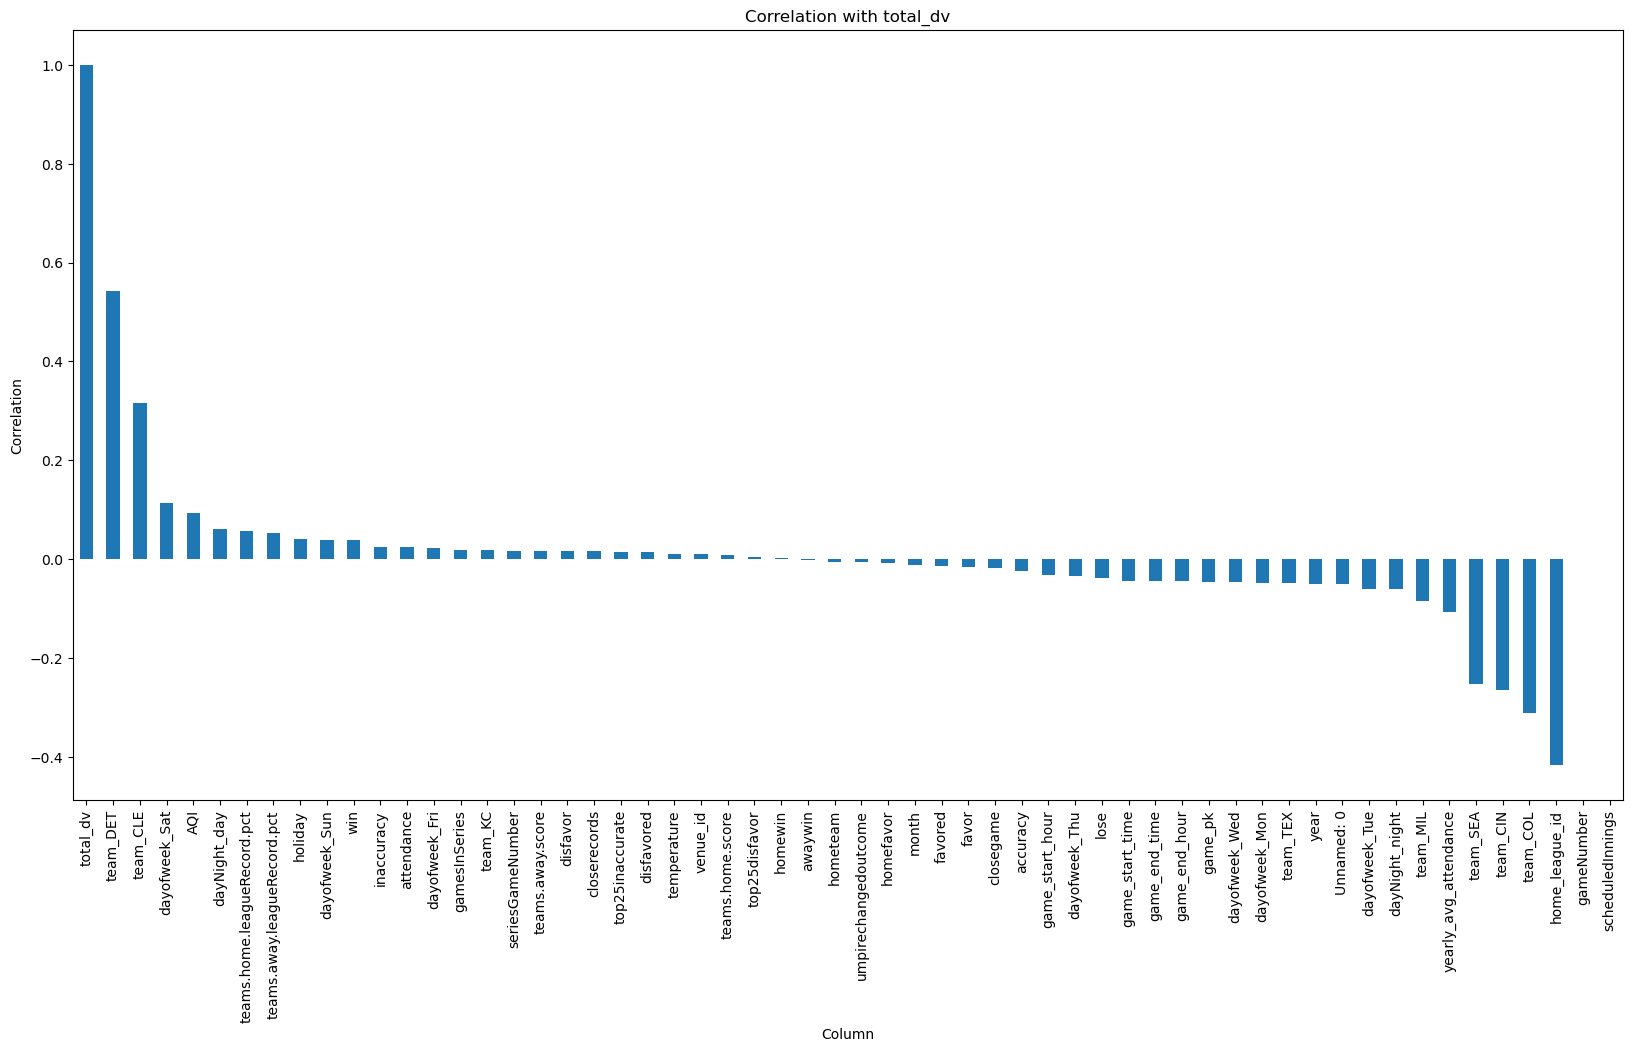

In [7]:
# Bar chart of correlations with "total_dv", only with numerical columns
total_dv_corr = mlb_dv_train[[c for c in mlb_dv_train.columns if not str(c).startswith("dv") or c == "total_dv"]].select_dtypes(include="number").corr()["total_dv"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(20, 10))
total_dv_corr.plot(kind="bar", ax=ax)
ax.set_title("Correlation with total_dv")
ax.set_xlabel("Column")
ax.set_ylabel("Correlation")
plt.show()

In [8]:
X_train = mlb_dv_train[[c for c in mlb_dv_train.columns if not str(c).startswith("dv") and not c == "total_dv"]].select_dtypes(include="number")
y_train = mlb_dv_train["total_dv"]

X_val = mlb_dv_val[[c for c in mlb_dv_val.columns if not str(c).startswith("dv") and not c == "total_dv"]].select_dtypes(include="number")
y_val = mlb_dv_val["total_dv"]

X_test = mlb_dv_test[[c for c in mlb_dv_test.columns if not str(c).startswith("dv") and not c == "total_dv"]].select_dtypes(include="number")
y_test = mlb_dv_test["total_dv"]

# Align columns to match the training features exactly
X_val = X_val.reindex(columns=X_train.columns, fill_value=0.0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0.0)

# Create evaluate function

In [9]:
# Evaluate on all three sets
def evaluate(model, name, X, y):
    y_pred = model.predict(X)
    mse = mean_squared_error(y, y_pred)
    return {
        "Set": name,
        "MAE": mean_absolute_error(y, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y, y_pred),
    }

# Linear Regression (Baseline)

In [10]:
baseline_lin = LinearRegression()
baseline_lin.fit(X_train, y_train)
y_pred_lin = baseline_lin.predict(X_test)

linreg_scores = pd.DataFrame([
    evaluate(baseline_lin, "Linear Train", X_train, y_train),
    evaluate(baseline_lin, "Linear Validation", X_val, y_val),
    evaluate(baseline_lin, "Linear Test", X_test, y_test),
]).set_index("Set")
print(linreg_scores)

mae_lin, mse_lin, rmse_lin, r2_lin = linreg_scores.loc["Linear Test"]

                        MAE        MSE      RMSE        R2
Set                                                       
Linear Train       2.290162   8.682235  2.946563  0.573609
Linear Validation  3.058209  19.209252  4.382836  0.164764
Linear Test        3.041231  16.802112  4.099038  0.200281


# ElasticNet Regression

In [11]:
scaler = StandardScaler().fit(X_train)
Xtr = scaler.transform(X_train)
Xva = scaler.transform(X_val)
Xte = scaler.transform(X_test)

In [12]:
# Tune alpha and l1_ratio on the validation set
alphas = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0]
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9, 1.0]

elastic_results = []
for alpha in alphas:
    for l1 in l1_ratios:
        model = ElasticNet(alpha=alpha, l1_ratio=l1, max_iter=10000, random_state=42)
        model.fit(Xtr, y_train)
        pred = model.predict(Xva)
        elastic_results.append({
            "alpha": alpha,
            "l1_ratio": l1,
            "val_rmse": np.sqrt(mean_squared_error(y_val, pred)),
            "val_mae": mean_absolute_error(y_val, pred),
        })

elastic_results = pd.DataFrame(elastic_results).sort_values("val_rmse").reset_index(drop=True)
print(elastic_results.head(10))

   alpha  l1_ratio  val_rmse   val_mae
0  0.300       0.1  4.340794  3.064120
1  0.100       0.1  4.362166  3.035971
2  0.100       0.3  4.370754  3.051938
3  0.100       0.5  4.379877  3.068462
4  0.300       0.3  4.382490  3.130577
5  0.001       0.1  4.387014  3.054257
6  0.001       0.3  4.387577  3.054264
7  0.001       0.5  4.388159  3.054265
8  0.001       0.7  4.388831  3.054280
9  0.030       0.1  4.389618  3.041190


In [13]:
best = elastic_results.iloc[0]

# Refit best model on train, check train vs. validation
best_elastic = ElasticNet(alpha=best["alpha"], l1_ratio=best["l1_ratio"],
                        max_iter=10000, random_state=42).fit(Xtr, y_train)

In [14]:
elastic_scores = pd.DataFrame([
    evaluate(best_elastic, "Elastic Train", Xtr, y_train),
    evaluate(best_elastic, "Elastic Validation", Xva, y_val),
    evaluate(best_elastic, "Elastic Test", Xte, y_test),
]).set_index("Set")
print(elastic_scores)

mae_elastic, mse_elastic, rmse_elastic, r2_elastic = elastic_scores.loc["Elastic Test"]

                         MAE        MSE      RMSE        R2
Set                                                        
Elastic Train       2.369228   9.210489  3.034879  0.547666
Elastic Validation  3.064120  18.842497  4.340794  0.180711
Elastic Test        3.020321  16.761258  4.094052  0.202226


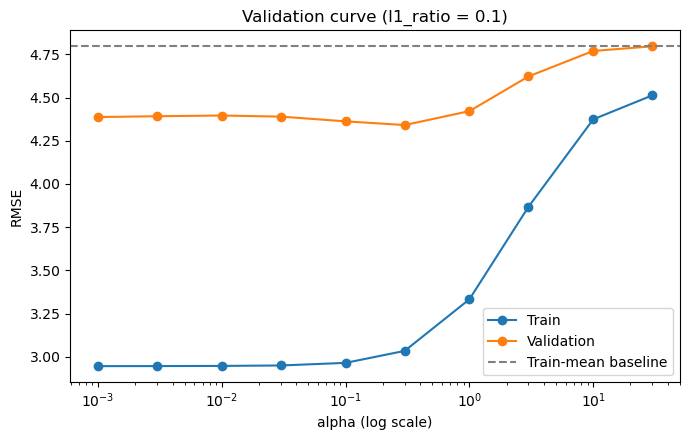

In [15]:
best_l1 = best["l1_ratio"]
rows = []
for alpha in alphas:
    m = ElasticNet(alpha=alpha, l1_ratio=best_l1, max_iter=10000, random_state=42).fit(Xtr, y_train)
    rows.append({
        "alpha": alpha,
        "train_rmse": np.sqrt(mean_squared_error(y_train, m.predict(Xtr))),
        "val_rmse": np.sqrt(mean_squared_error(y_val, m.predict(Xva))),
    })
curve = pd.DataFrame(rows)

plt.figure(figsize=(7, 4.5))
plt.plot(curve["alpha"], curve["train_rmse"], "o-", label="Train")
plt.plot(curve["alpha"], curve["val_rmse"], "o-", label="Validation")
plt.axhline(np.sqrt(mean_squared_error(y_val, np.full(len(y_val), y_train.mean()))),
            color="gray", ls="--", label="Train-mean baseline")
plt.xscale("log")
plt.xlabel("alpha (log scale)")
plt.ylabel("RMSE")
plt.title(f"Validation curve (l1_ratio = {best_l1})")
plt.legend()
plt.tight_layout()
plt.show()

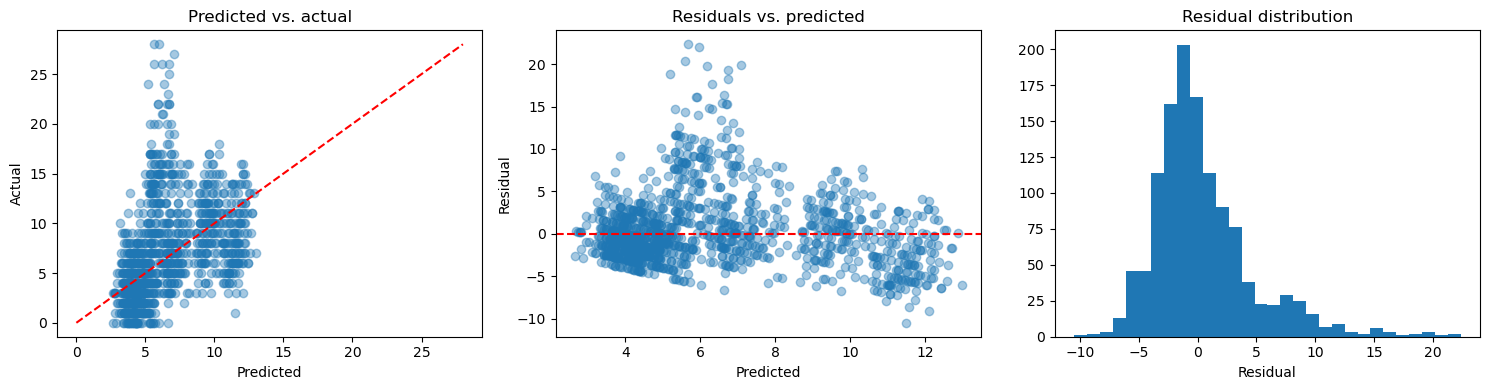

In [16]:
# Predicted vs. actual on the test set
pred = best_elastic.predict(Xva)
resid = y_val - pred

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(pred, y_val, alpha=0.4)
lims = [min(pred.min(), y_val.min()), max(pred.max(), y_val.max())]
ax[0].plot(lims, lims, "r--")
ax[0].set(xlabel="Predicted", ylabel="Actual", title="Predicted vs. actual")

ax[1].scatter(pred, resid, alpha=0.4)
ax[1].axhline(0, color="r", ls="--")
ax[1].set(xlabel="Predicted", ylabel="Residual", title="Residuals vs. predicted")

ax[2].hist(resid, bins=30)
ax[2].set(xlabel="Residual", title="Residual distribution")
plt.tight_layout()
plt.show()

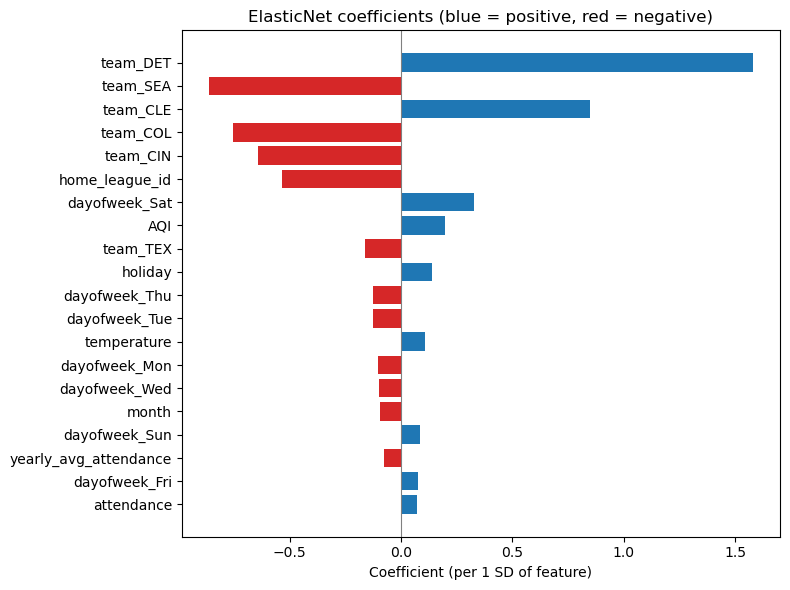

In [17]:
coefs = pd.Series(best_elastic.coef_, index=X_train.columns)
nonzero = coefs[coefs != 0]
top = nonzero.reindex(nonzero.abs().sort_values(ascending=False).index).head(20)

colors = ["tab:red" if v < 0 else "tab:blue" for v in top.values[::-1]]
plt.figure(figsize=(8, 6))
plt.barh(top.index[::-1], top.values[::-1], color=colors)
plt.axvline(0, color="gray", lw=0.8)
plt.xlabel("Coefficient (per 1 SD of feature)")
plt.title("ElasticNet coefficients (blue = positive, red = negative)")
plt.tight_layout()
plt.show()

# XGBoost Regression

In [18]:
# XGBoost model: train on train, early stop on validation
xgb_model = XGBRegressor(
    n_estimators=2000,          # upper bound; early stopping picks the actual number
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=1,
    reg_lambda=1.0,
    objective="reg:squarederror",
    eval_metric="rmse",
    early_stopping_rounds=50,
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
)

xgb_model.fit(
    X_train, y_train,
    # Early stopping watches the LAST set, so validation must come last
    eval_set=[(X_train, y_train), (X_test, y_test), (X_val, y_val)],
    verbose=100,
)

print(f"Best iteration: {xgb_model.best_iteration}")
print(f"Best validation RMSE: {xgb_model.best_score:.4f}")

[0]	validation_0-rmse:4.38705	validation_1-rmse:4.50797	validation_2-rmse:4.70673
[100]	validation_0-rmse:2.33760	validation_1-rmse:3.21242	validation_2-rmse:3.32950
[200]	validation_0-rmse:2.08113	validation_1-rmse:3.20373	validation_2-rmse:3.30631
[300]	validation_0-rmse:1.84064	validation_1-rmse:3.19995	validation_2-rmse:3.30824
[312]	validation_0-rmse:1.81434	validation_1-rmse:3.20032	validation_2-rmse:3.30812
Best iteration: 262
Best validation RMSE: 3.2991


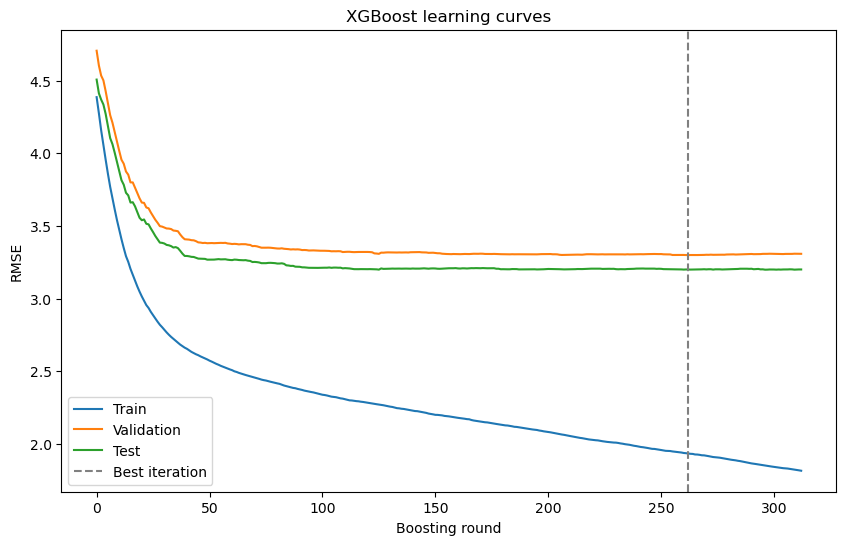

In [19]:
# Learning curves: train vs. validation vs. test RMSE
results = xgb_model.evals_result()
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(results["validation_0"]["rmse"], label="Train")
ax.plot(results["validation_2"]["rmse"], label="Validation")
ax.plot(results["validation_1"]["rmse"], label="Test")
ax.axvline(xgb_model.best_iteration, color="gray", linestyle="--", label="Best iteration")
ax.set_xlabel("Boosting round")
ax.set_ylabel("RMSE")
ax.set_title("XGBoost learning curves")
ax.legend()
plt.show()

In [20]:
xgb_scores = pd.DataFrame([
    evaluate(xgb_model, "XGB Train", X_train, y_train),
    evaluate(xgb_model, "XGB Validation", X_val, y_val),
    evaluate(xgb_model, "XGB Test", X_test, y_test),
]).set_index("Set")
print(xgb_scores)

# Test-set metrics, named for the comparison with the linear baseline
y_pred_xgb = xgb_model.predict(X_test)
mae_xgb, mse_xgb, rmse_xgb, r2_xgb = xgb_scores.loc["XGB Test"]

                     MAE        MSE      RMSE        R2
Set                                                    
XGB Train       1.508129   3.735562  1.932760  0.816544
XGB Validation  2.397565  10.883895  3.299075  0.526758
XGB Test        2.472844  10.237032  3.199536  0.512755


In [21]:
# Side-by-side comparison with the linear baseline
comparison = pd.DataFrame({
    "Linear Regression": [mae_lin, mse_lin, rmse_lin, r2_lin],
    "ElasticNet": [mae_elastic, mse_elastic, rmse_elastic, r2_elastic],
    "XGBoost": [mae_xgb, mse_xgb, rmse_xgb, r2_xgb],
}, index=["MAE", "MSE", "RMSE", "R2"])
print(comparison)

      Linear Regression  ElasticNet    XGBoost
MAE            3.041231    3.020321   2.472844
MSE           16.802112   16.761258  10.237032
RMSE           4.099038    4.094052   3.199536
R2             0.200281    0.202226   0.512755


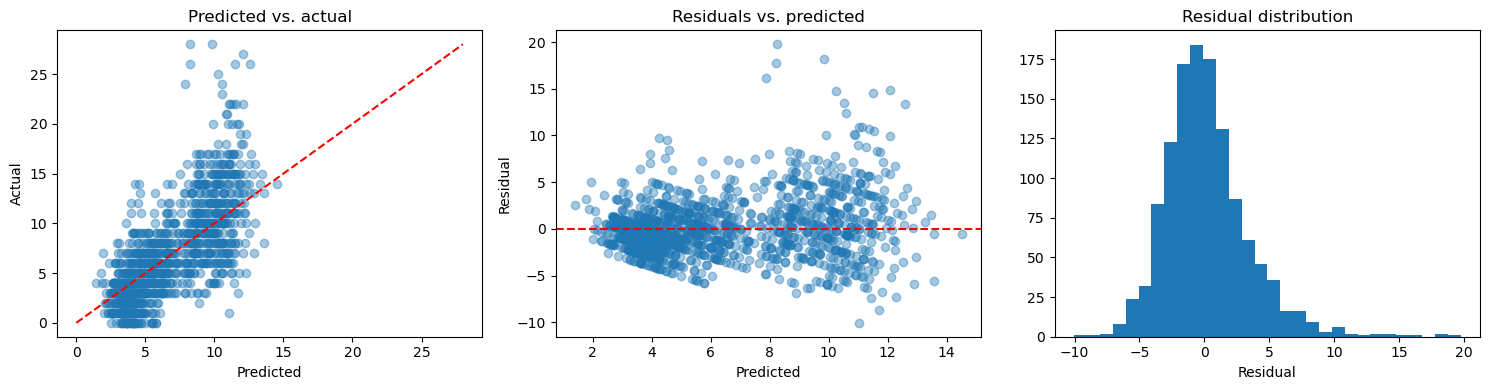

In [22]:
# Predicted vs. actual on the test set
pred = xgb_model.predict(X_val)
resid = y_val - pred

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(pred, y_val, alpha=0.4)
lims = [min(pred.min(), y_val.min()), max(pred.max(), y_val.max())]
ax[0].plot(lims, lims, "r--")
ax[0].set(xlabel="Predicted", ylabel="Actual", title="Predicted vs. actual")

ax[1].scatter(pred, resid, alpha=0.4)
ax[1].axhline(0, color="r", ls="--")
ax[1].set(xlabel="Predicted", ylabel="Residual", title="Residuals vs. predicted")

ax[2].hist(resid, bins=30)
ax[2].set(xlabel="Residual", title="Residual distribution")
plt.tight_layout()
plt.show()

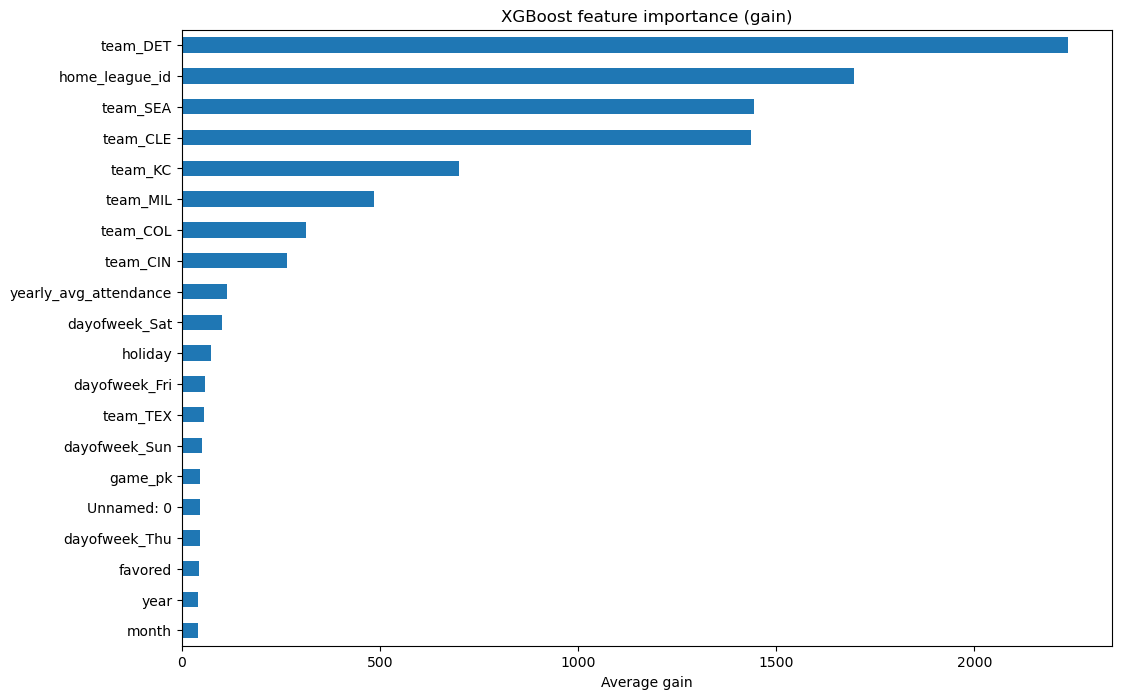

In [23]:
# Feature importance (gain) — top 25 features
importance = pd.Series(
    xgb_model.get_booster().get_score(importance_type="gain")
).sort_values(ascending=False).head(20)

fig, ax = plt.subplots(figsize=(12, 8))
importance.sort_values().plot(kind="barh", ax=ax)
ax.set_title("XGBoost feature importance (gain)")
ax.set_xlabel("Average gain")
plt.show()

# Random Forest Regression

In [24]:
min_leafs = [10, 20, 40, 80]
max_feats = [0.2, 0.4, 0.6]

rf_results = []
for leaf in min_leafs:
    for mf in max_feats:
        rf = RandomForestRegressor(
            n_estimators=100, min_samples_leaf=leaf, max_features=mf,
            n_jobs=-1, random_state=42
        ).fit(X_train, y_train)
        pred = rf.predict(X_val)
        rf_results.append({
            "min_samples_leaf": leaf,
            "max_features": mf,
            "val_rmse": np.sqrt(mean_squared_error(y_val, pred)),
            "val_mae": mean_absolute_error(y_val, pred),
        })

rf_results = pd.DataFrame(rf_results).sort_values("val_rmse").reset_index(drop=True)
print(rf_results.head(10))

   min_samples_leaf  max_features  val_rmse   val_mae
0                10           0.6  3.197706  2.341026
1                20           0.6  3.253105  2.390644
2                10           0.4  3.266354  2.392350
3                20           0.4  3.447677  2.515701
4                10           0.2  3.583114  2.616184
5                40           0.6  3.785704  2.686266
6                40           0.4  3.882831  2.758148
7                20           0.2  3.932732  2.842631
8                40           0.2  4.086303  2.950011
9                80           0.6  4.210618  2.946102


In [25]:
best_rf = rf_results.iloc[0]

# Refit best model on train, check train vs. validation
best_rf_model = RandomForestRegressor(
    n_estimators=500, min_samples_leaf=int(best_rf["min_samples_leaf"]), max_features=best_rf["max_features"],
    n_jobs=-1, random_state=42).fit(X_train, y_train)

In [26]:
rf_scores = pd.DataFrame([
    evaluate(best_rf_model, "RF Train", X_train, y_train),
    evaluate(best_rf_model, "RF Validation", X_val, y_val),
    evaluate(best_rf_model, "RF Test", X_test, y_test),
]).set_index("Set")
print(rf_scores)

mae_rf, mse_rf, rmse_rf, r2_rf = rf_scores.loc["RF Test"]

                    MAE        MSE      RMSE        R2
Set                                                   
RF Train       1.699561   4.928157  2.219945  0.757975
RF Validation  2.344613  10.256143  3.202521  0.554053
RF Test        2.351241   9.488342  3.080315  0.548390


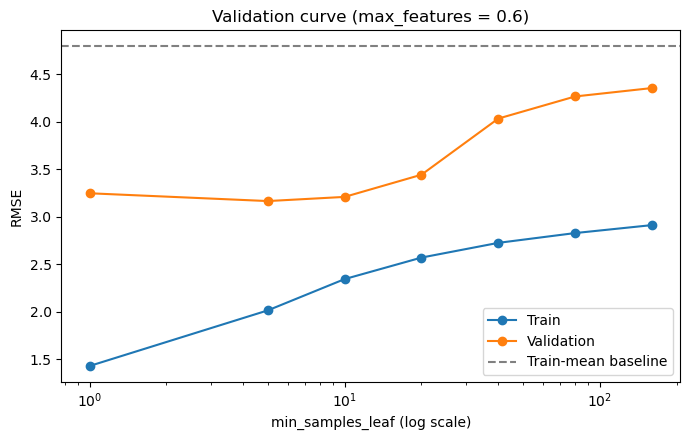

In [27]:
best_mf = rf_results.iloc[0]["max_features"]
rows = []
for leaf in [1, 5, 10, 20, 40, 80, 160]:
    m = RandomForestRegressor(n_estimators=100, min_samples_leaf=leaf, max_features=best_mf,
                              max_samples=0.7, n_jobs=-1, random_state=42).fit(X_train, y_train)
    rows.append({
        "leaf": leaf,
        "train_rmse": np.sqrt(mean_squared_error(y_train, m.predict(X_train))),
        "val_rmse": np.sqrt(mean_squared_error(y_val, m.predict(X_val))),
    })
curve = pd.DataFrame(rows)

plt.figure(figsize=(7, 4.5))
plt.plot(curve["leaf"], curve["train_rmse"], "o-", label="Train")
plt.plot(curve["leaf"], curve["val_rmse"], "o-", label="Validation")
plt.axhline(np.sqrt(mean_squared_error(y_val, np.full(len(y_val), y_train.mean()))),
            color="gray", ls="--", label="Train-mean baseline")
plt.xscale("log")
plt.xlabel("min_samples_leaf (log scale)")
plt.ylabel("RMSE")
plt.title(f"Validation curve (max_features = {best_mf})")
plt.legend()
plt.tight_layout()
plt.show()

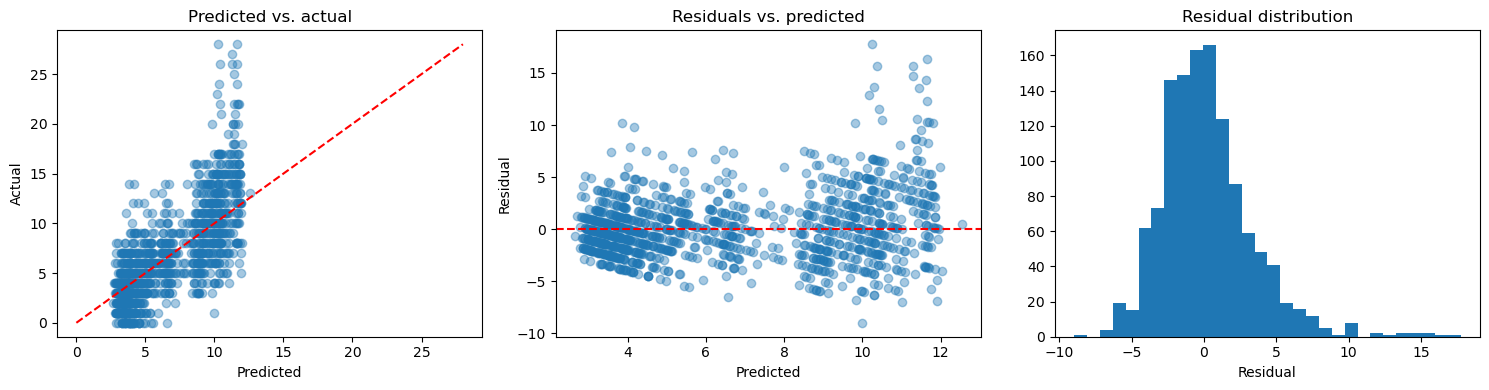

In [28]:
pred = best_rf_model.predict(X_val)
resid = y_val - pred

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(pred, y_val, alpha=0.4)
lims = [min(pred.min(), y_val.min()), max(pred.max(), y_val.max())]
ax[0].plot(lims, lims, "r--")
ax[0].set(xlabel="Predicted", ylabel="Actual", title="Predicted vs. actual")

ax[1].scatter(pred, resid, alpha=0.4)
ax[1].axhline(0, color="r", ls="--")
ax[1].set(xlabel="Predicted", ylabel="Residual", title="Residuals vs. predicted")

ax[2].hist(resid, bins=30)
ax[2].set(xlabel="Residual", title="Residual distribution")
plt.tight_layout()
plt.show()

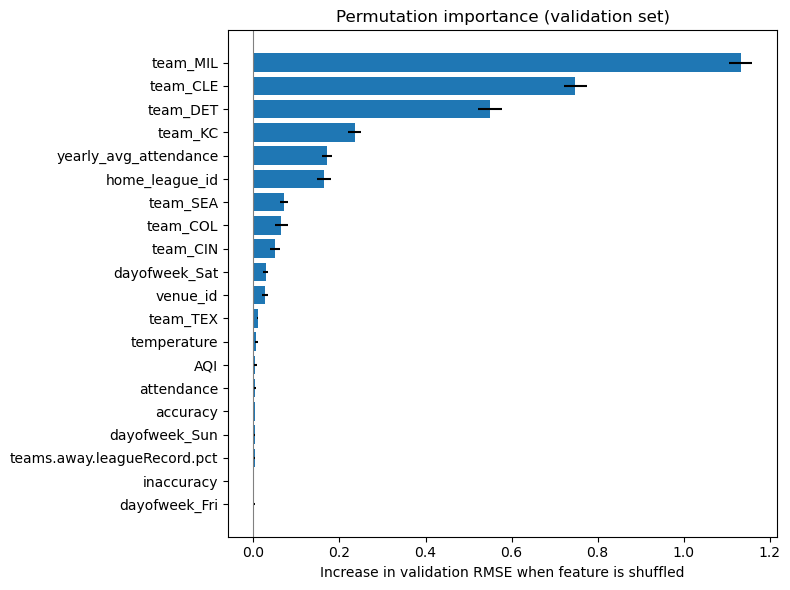

In [29]:
r = permutation_importance(
    best_rf_model, X_val, y_val, n_repeats=10, random_state=42,
    scoring="neg_root_mean_squared_error", n_jobs=-1
)

imp = pd.Series(r.importances_mean, index=X_val.columns)
err = pd.Series(r.importances_std, index=X_val.columns)
order = imp.sort_values(ascending=False).head(20).index

plt.figure(figsize=(8, 6))
plt.barh(order[::-1], imp[order][::-1], xerr=err[order][::-1])
plt.axvline(0, color="gray", lw=0.8)
plt.xlabel("Increase in validation RMSE when feature is shuffled")
plt.title("Permutation importance (validation set)")
plt.tight_layout()
plt.show()

In [30]:
comparison = pd.DataFrame({
    "Linear Regression": [mae_lin, mse_lin, rmse_lin, r2_lin],
    "ElasticNet": [mae_elastic, mse_elastic, rmse_elastic, r2_elastic],
    "XGBoost": [mae_xgb, mse_xgb, rmse_xgb, r2_xgb],
    "Random Forest": [mae_rf, mse_rf, rmse_rf, r2_rf],
    }, index=["MAE", "MSE", "RMSE", "R2"])
print(comparison)

      Linear Regression  ElasticNet    XGBoost  Random Forest
MAE            3.041231    3.020321   2.472844       2.351241
MSE           16.802112   16.761258  10.237032       9.488342
RMSE           4.099038    4.094052   3.199536       3.080315
R2             0.200281    0.202226   0.512755       0.548390


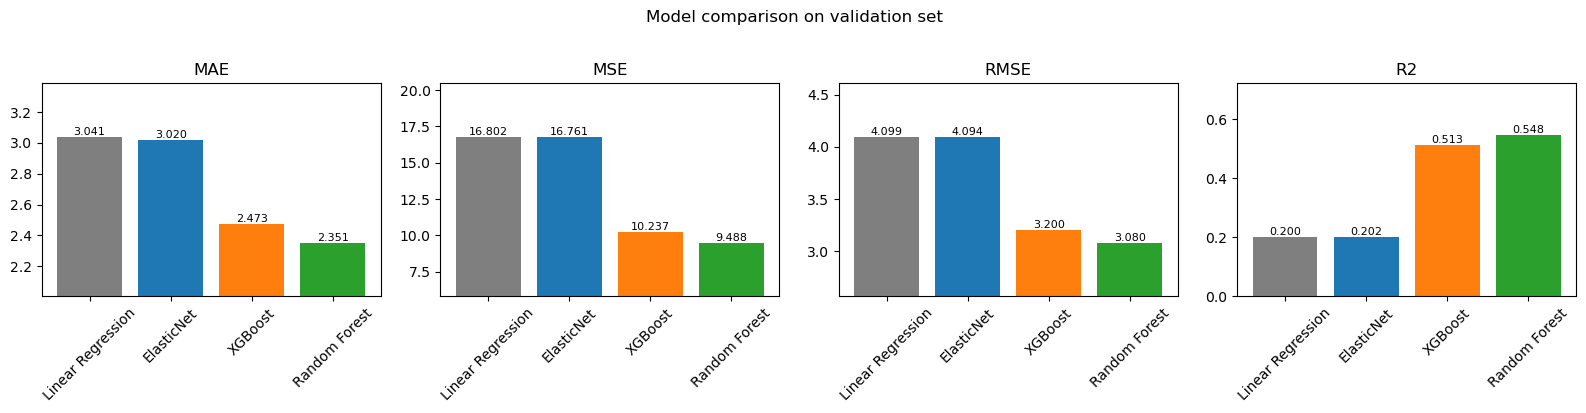

In [31]:
# Bar chart for comparison table
models = comparison.columns
colors = ["tab:gray", "tab:blue", "tab:orange", "tab:green"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, metric in zip(axes, comparison.index):
    vals = comparison.loc[metric]
    bars = ax.bar(models, vals, color=colors)
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=45)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{v:.3f}",
                ha="center", va="bottom", fontsize=8)

    # Zoom the y-axis so small differences are visible (bars still start from the axis floor)
    lo, hi = vals.min(), vals.max()
    pad = (hi - lo) * 0.5 or 0.1
    ax.set_ylim(max(0, lo - pad) if metric != "R2" else min(0, lo - pad), hi + pad)

fig.suptitle("Model comparison on validation set", y=1.02)
plt.tight_layout()
plt.show()

# Models without Umpire Accuracy

In [32]:
X_train_no_ump = X_train.drop(columns=['homefavor', 'accuracy', 'umpirechangedoutcome', 'inaccuracy', 'favor', 'disfavor', 'favored', 'disfavored', 'top25inaccurate', 'top25disfavor'])
X_val_no_ump = X_val.drop(columns=['homefavor', 'accuracy', 'umpirechangedoutcome', 'inaccuracy', 'favor', 'disfavor', 'favored', 'disfavored', 'top25inaccurate', 'top25disfavor'])
X_test_no_ump = X_test.drop(columns=['homefavor', 'accuracy', 'umpirechangedoutcome', 'inaccuracy', 'favor', 'disfavor', 'favored', 'disfavored', 'top25inaccurate', 'top25disfavor'])

In [33]:
# Baseline linear regression
baseline_lin_no_ump = LinearRegression()
baseline_lin_no_ump.fit(X_train_no_ump, y_train)
y_pred_lin_no_ump = baseline_lin_no_ump.predict(X_test_no_ump)

linreg_scores_no_ump = pd.DataFrame([
    evaluate(baseline_lin_no_ump, "Linear Train", X_train_no_ump, y_train),
    evaluate(baseline_lin_no_ump, "Linear Validation", X_val_no_ump, y_val),
    evaluate(baseline_lin_no_ump, "Linear Test", X_test_no_ump, y_test),
]).set_index("Set")

mae_lin_no_ump, mse_lin_no_ump, rmse_lin_no_ump, r2_lin_no_ump = linreg_scores_no_ump.loc["Linear Test"]

# Elastic net
scaler2 = StandardScaler().fit(X_train_no_ump)
Xtr_no_ump = scaler2.transform(X_train_no_ump)
Xva_no_ump = scaler2.transform(X_val_no_ump)
Xte_no_ump = scaler2.transform(X_test_no_ump)

best_elastic_no_ump = ElasticNet(alpha=best["alpha"], l1_ratio=best["l1_ratio"],
                        max_iter=10000, random_state=42).fit(Xtr_no_ump, y_train)

elastic_scores_no_ump = pd.DataFrame([
    evaluate(best_elastic_no_ump, "Elastic Train", Xtr_no_ump, y_train),
    evaluate(best_elastic_no_ump, "Elastic Validation", Xva_no_ump, y_val),
    evaluate(best_elastic_no_ump, "Elastic Test", Xte_no_ump, y_test),
]).set_index("Set")

mae_elastic_no_ump, mse_elastic_no_ump, rmse_elastic_no_ump, r2_elastic_no_ump = elastic_scores_no_ump.loc["Elastic Test"]

# XGBoost
xgb_model.fit(
    X_train_no_ump, y_train,
    eval_set=[(X_train_no_ump, y_train), (X_test_no_ump, y_test), (X_val_no_ump, y_val)],
    verbose=100,
)

xgb_scores_no_ump = pd.DataFrame([
    evaluate(xgb_model, "XGB Train", X_train_no_ump, y_train),
    evaluate(xgb_model, "XGB Validation", X_val_no_ump, y_val),
    evaluate(xgb_model, "XGB Test", X_test_no_ump, y_test),
]).set_index("Set")

y_pred_xgb_no_ump = xgb_model.predict(X_test_no_ump)
mae_xgb_no_ump, mse_xgb_no_ump, rmse_xgb_no_ump, r2_xgb_no_ump = xgb_scores_no_ump.loc["XGB Test"]

# Random Forest
best_rf_no_ump = RandomForestRegressor(
    n_estimators=500, min_samples_leaf=int(best_rf["min_samples_leaf"]), max_features=best_rf["max_features"],
    n_jobs=-1, random_state=42).fit(X_train_no_ump, y_train)

rf_scores_no_ump = pd.DataFrame([
    evaluate(best_rf_no_ump, "RF Train", X_train_no_ump, y_train),
    evaluate(best_rf_no_ump, "RF Validation", X_val_no_ump, y_val),
    evaluate(best_rf_no_ump, "RF Test", X_test_no_ump, y_test),
]).set_index("Set")

mae_rf_no_ump, mse_rf_no_ump, rmse_rf_no_ump, r2_rf_no_ump = rf_scores_no_ump.loc["RF Test"]

[0]	validation_0-rmse:4.37839	validation_1-rmse:4.51431	validation_2-rmse:4.73409
[100]	validation_0-rmse:2.36219	validation_1-rmse:3.31461	validation_2-rmse:3.44760
[200]	validation_0-rmse:2.11442	validation_1-rmse:3.23915	validation_2-rmse:3.39624
[255]	validation_0-rmse:1.99280	validation_1-rmse:3.24027	validation_2-rmse:3.39306


In [34]:
comparison_no_ump = pd.DataFrame({
    "Linear Regression": [mae_lin_no_ump, mse_lin_no_ump, rmse_lin_no_ump, r2_lin_no_ump],
    "ElasticNet": [mae_elastic_no_ump, mse_elastic_no_ump, rmse_elastic_no_ump, r2_elastic_no_ump],
    "XGBoost": [mae_xgb_no_ump, mse_xgb_no_ump, rmse_xgb_no_ump, r2_xgb_no_ump],
    "Random Forest": [mae_rf_no_ump, mse_rf_no_ump, rmse_rf_no_ump, r2_rf_no_ump],
    }, index=["MAE", "MSE", "RMSE", "R2"])
print(comparison_no_ump)

      Linear Regression  ElasticNet    XGBoost  Random Forest
MAE            3.041912    3.020257   2.497304       2.322644
MSE           16.788144   16.760180  10.494348       9.319285
RMSE           4.097334    4.093920   3.239498       3.052750
R2             0.200946    0.202277   0.500508       0.556436


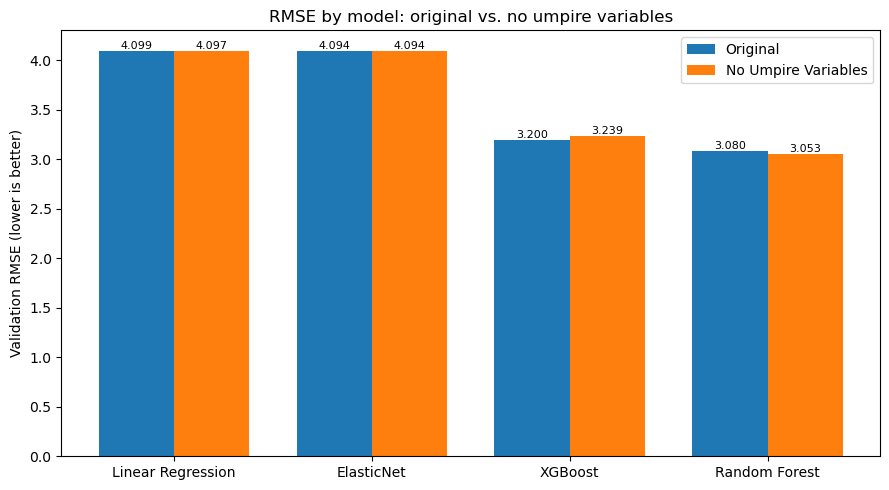

In [35]:
# Bar chart comparing ump variables vs. no ump variables
labels_a = "Original"        # name for the first set of models
labels_b = "No Umpire Variables"         # name for the second set of models

rmse_a = comparison.loc["RMSE"].values
rmse_b = comparison_no_ump.loc["RMSE"].values
pair_names = comparison.columns            # one label per pair

x = np.arange(len(pair_names))
w = 0.38

fig, ax = plt.subplots(figsize=(9, 5))
bars_a = ax.bar(x - w/2, rmse_a, w, label=labels_a, color="tab:blue")
bars_b = ax.bar(x + w/2, rmse_b, w, label=labels_b, color="tab:orange")

for bars in (bars_a, bars_b):
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height(), f"{b.get_height():.3f}",
                ha="center", va="bottom", fontsize=8)

# Optional: a dashed line for the train-mean baseline
# ax.axhline(baseline_rmse, color="k", ls="--", label="Train-mean baseline")

ax.set_xticks(x)
ax.set_xticklabels(pair_names)
ax.set_ylabel("Validation RMSE (lower is better)")
ax.set_title("RMSE by model: original vs. no umpire variables")
ax.legend()
plt.tight_layout()
plt.show()